<a href="https://colab.research.google.com/github/tomvangasse/ATLAS-top-tagging-ML-project/blob/main/explore_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Get URLs for the test dataset

In [9]:
!pip install cernopendata-client
!cernopendata-client get-file-locations --recid 80030 --protocol http | grep -i test | head

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.0/116.0 kB 9.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for cernopendata-client: filename=cernopendata_client-1.0.2-py2.py3-none-any.whl size=36624 sha256=1ced7610d491686195ba0efa07c7bab77d2e3bd5d93e019f86466e2b4124f9d8
  Stored in directory: /root/.cache/pip/wheels/1f/8d/0a/c64e8a315d8256ebe4de86fdb25365207da720e81815d3c0ec
Successfully built cernopendata-client
http://opendata.cern.ch/eos/opendata/atlas/datascience/CERN-EP-2024-159/test_nominal_000.h5.gz
http://opendata.cern.ch/eos/opendata/atlas/datascience/CERN-EP-2024-159/test_nominal_001.h5.gz
http://opendata.cern.ch/eos/opendata/atlas/datascience/CERN-EP-2024-159/test_nominal_010.h5.gz
http://opendata.cern.ch/eos/opendata/atlas/datascience/CERN-EP-2024-159/test_nominal_100.h5.gz
http://opendata.cern.ch/eos/opendata/atlas/datascience/CERN-EP-2024-159/test_nominal_101.h5.gz
http://opendata.cern.ch/eos/opendata/atlas/datascience/CERN-EP-2024-159/test_

## Downloading and unzipping a small sample of the dataset

In [13]:
!pip install h5py mplhep xgboost
!wget -O test.h5 "http://opendata.cern.ch/eos/opendata/atlas/datascience/CERN-EP-2024-159/test_nominal_000.h5.gz"
!mv test.h5 test_nominal_0.h5.gz
!gunzip test_nominal_0.h5.gz
!ls -lh test_nominal_0.h5

URL transformed to HTTPS due to an HSTS policy
--2026-10-17 13:18:01--  https://opendata.cern.ch/eos/opendata/atlas/datascience/CERN-EP-2024-159/test_nominal_000.h5.gz
Resolving opendata.cern.ch (opendata.cern.ch)... 137.138.6.31, 2001:1458:201:8b::100:1c8
Connecting to opendata.cern.ch (opendata.cern.ch)|137.138.6.31|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 96662577 (92M) [application/octet-stream]
Saving to: ‘test.h5’

test.h5             100%[===================>]  92.18M  11.0MB/s    in 9.6s    

2026-10-17 13:18:13 (9.57 MB/s) - ‘test.h5’ saved [96662577/96662577]

-rw-r--r-- 1 root root 400M Jul 25  2024 test_nominal_0.h5


## Small scale data visualisation test

In [15]:
import h5py

f = h5py.File("test_nominal_0.h5", "r")
f.visit(print)  # lists every dataset name
for name in f.keys():
    print(name, f[name].shape, f[name].dtype)

EventInfo_mcEventNumber
EventInfo_mcEventWeights
fjet_C2
fjet_D2
fjet_ECF1
fjet_ECF2
fjet_ECF3
fjet_L2
fjet_L3
fjet_Qw
fjet_Split12
fjet_Split23
fjet_Tau1_wta
fjet_Tau2_wta
fjet_Tau3_wta
fjet_Tau4_wta
fjet_ThrustMaj
fjet_clus_E
fjet_clus_eta
fjet_clus_phi
fjet_clus_pt
fjet_clus_taste
fjet_eta
fjet_m
fjet_phi
fjet_pt
labels
EventInfo_mcEventNumber (100000,) int32
EventInfo_mcEventWeights (100000, 27) float32
fjet_C2 (100000,) float32
fjet_D2 (100000,) float32
fjet_ECF1 (100000,) float32
fjet_ECF2 (100000,) float32
fjet_ECF3 (100000,) float32
fjet_L2 (100000,) float32
fjet_L3 (100000,) float32
fjet_Qw (100000,) float32
fjet_Split12 (100000,) float32
fjet_Split23 (100000,) float32
fjet_Tau1_wta (100000,) float32
fjet_Tau2_wta (100000,) float32
fjet_Tau3_wta (100000,) float32
fjet_Tau4_wta (100000,) float32
fjet_ThrustMaj (100000,) float32
fjet_clus_E (100000, 200) float32
fjet_clus_eta (100000, 200) float32
fjet_clus_phi (100000, 200) float32
fjet_clus_pt (100000, 200) float32
fjet_clus_t

In [20]:
labels = f["fjet_C2"][:100000]  # read the first 100k rows only
print(labels[:10])

[0.19761609 0.15885165 0.04611588 0.01308021 0.10373674 0.09462645
 0.21674825 0.0390766  0.08163471 0.21982847]


## Visualising the data



### Using pandas to visualise the data

Pandas is a python library used to clean and interpret datasets


Im using it here to create a table to show the min, max, and the quartile values

In [22]:
import pandas as pd, numpy as np
N = 200000
with h5py.File("test_nominal_0.h5", "r") as f:
    data = {}
    for k in f.keys():  # loops over array in the file
        if f[k].ndim == 1:  # only keeps the 1D arrays
            data[k] = f[k][:N]
df = pd.DataFrame(data)
print(df.columns.tolist())
df.describe().T

['EventInfo_mcEventNumber', 'fjet_C2', 'fjet_D2', 'fjet_ECF1', 'fjet_ECF2', 'fjet_ECF3', 'fjet_L2', 'fjet_L3', 'fjet_Qw', 'fjet_Split12', 'fjet_Split23', 'fjet_Tau1_wta', 'fjet_Tau2_wta', 'fjet_Tau3_wta', 'fjet_Tau4_wta', 'fjet_ThrustMaj', 'fjet_eta', 'fjet_m', 'fjet_phi', 'fjet_pt', 'labels']


,count,mean,std,min,25%,50%,75%,max
EventInfo_mcEventNumber,100000.0,4.624823e+07,8.337810e+07,3.000000e+01,9.346698e+06,1.777651e+07,3.140020e+07,4.927544e+08
fjet_C2,100000.0,1.231481e-01,8.585595e-02,1.012138e-04,5.700617e-02,9.843598e-02,1.698015e-01,5.190319e-01
fjet_D2,100000.0,1.910816e+00,1.130557e+00,7.042637e-03,1.265521e+00,1.618396e+00,2.204741e+00,3.021197e+01
fjet_ECF1,100000.0,1.556408e+00,8.692657e-01,1.935845e-01,7.996105e-01,1.479957e+00,2.233950e+00,4.060662e+00
fjet_ECF2,100000.0,1.804124e-01,2.600169e-01,1.384200e-03,3.969628e-02,1.035232e-01,2.064563e-01,3.786102e+00
fjet_ECF3,100000.0,7.419785e-03,3.450967e-02,3.284368e-08,1.578827e-04,6.947688e-04,1.941061e-03,1.657995e+00
fjet_L2,100000.0,2.138669e-01,6.517076e-02,6.224078e-04,1.703230e-01,2.241218e-01,2.625598e-01,3.654651e-01
fjet_L3,100000.0,7.625279e-02,2.954232e-02,9.347521e-04,5.470305e-02,7.703399e-02,9.842468e-02,1.595805e-01
fjet_Qw,100000.0,7.192698e-02,5.792865e-02,6.277275e-04,3.292114e-02,6.135267e-02,8.790248e-02,8.061480e-01
fjet_Split12,100000.0,9.821597e-02,1.129246e-01,8.285288e-04,3.840933e-02,7.005467e-02,1.084974e-01,1.759000e+00


### Using matplotlib to create histograms


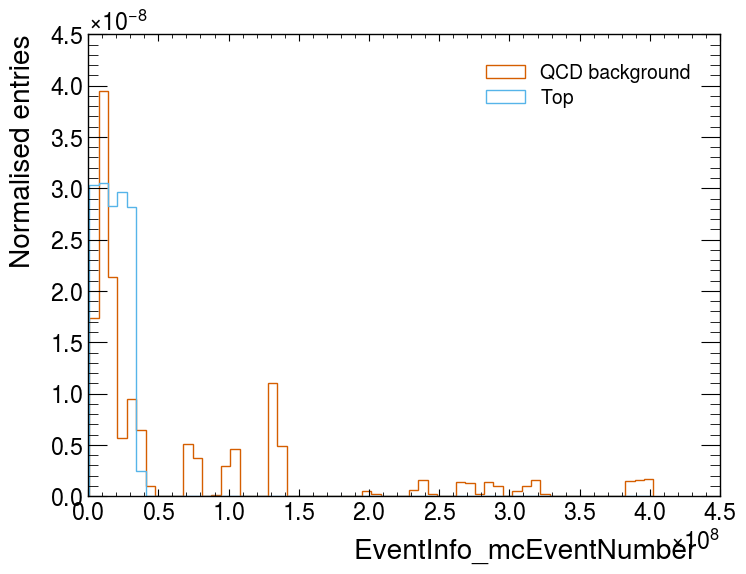

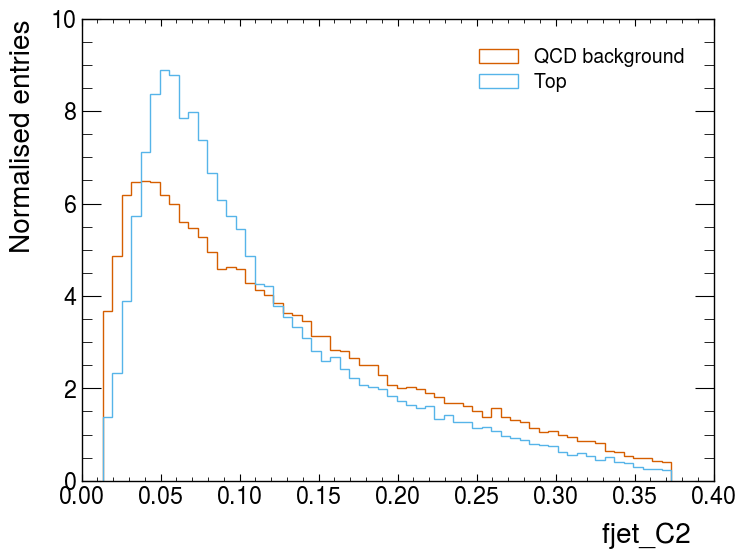

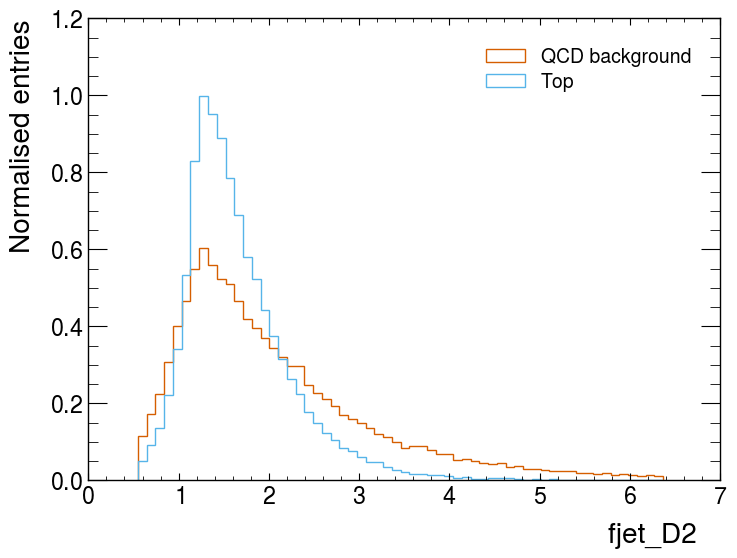

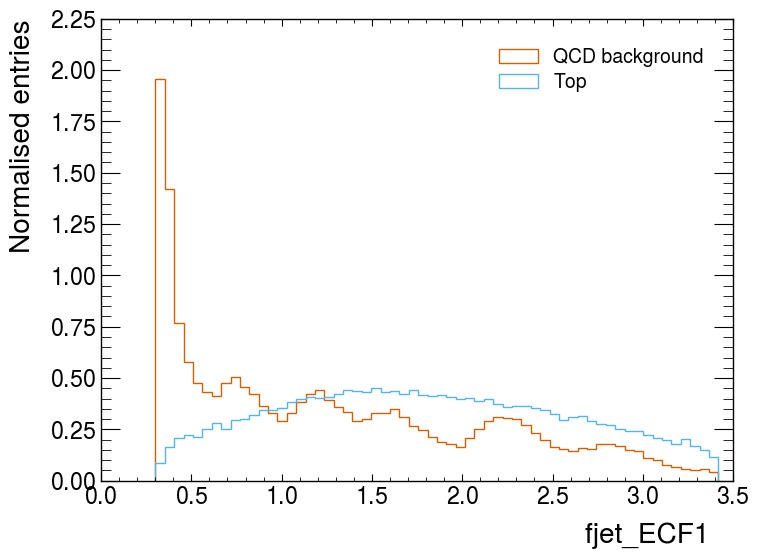

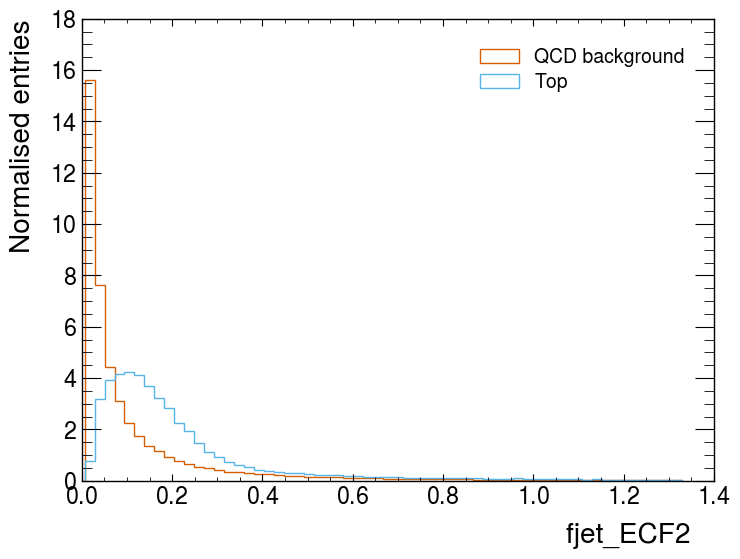

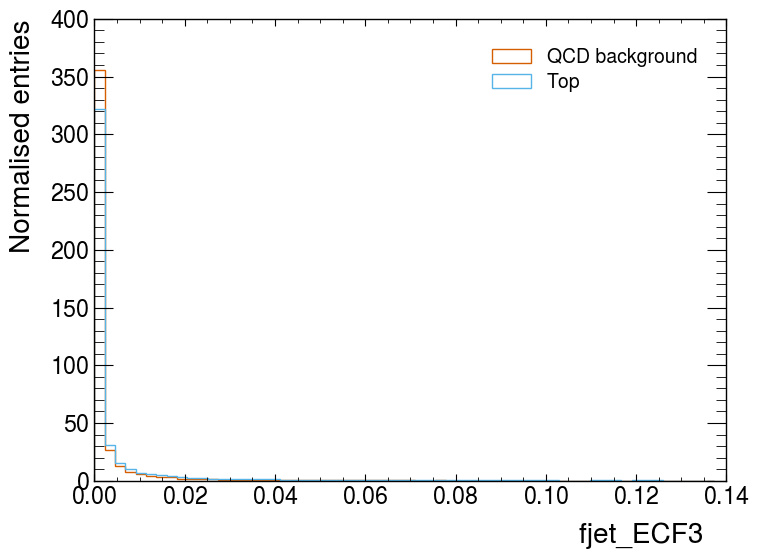

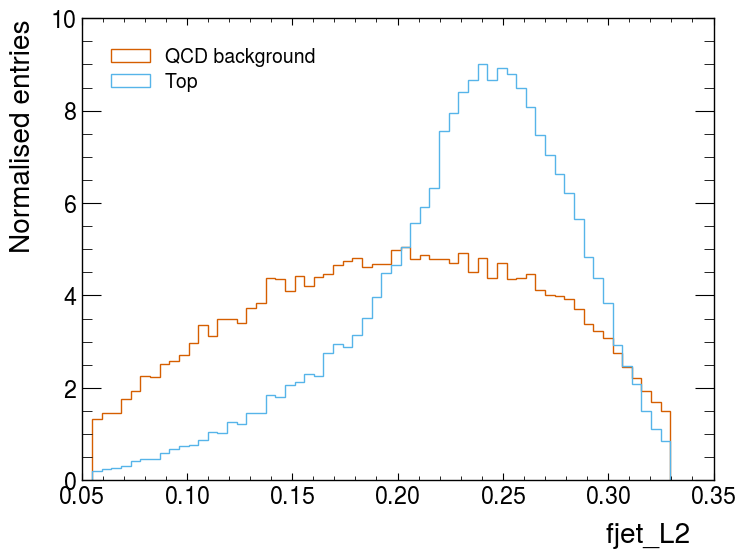

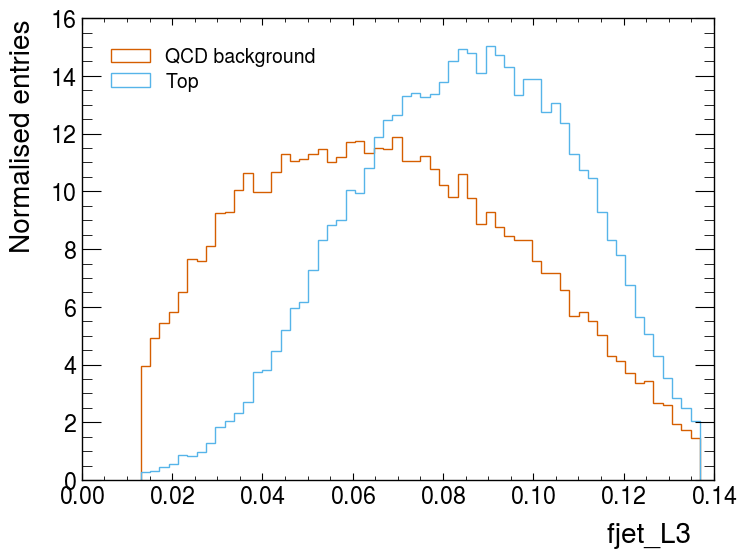

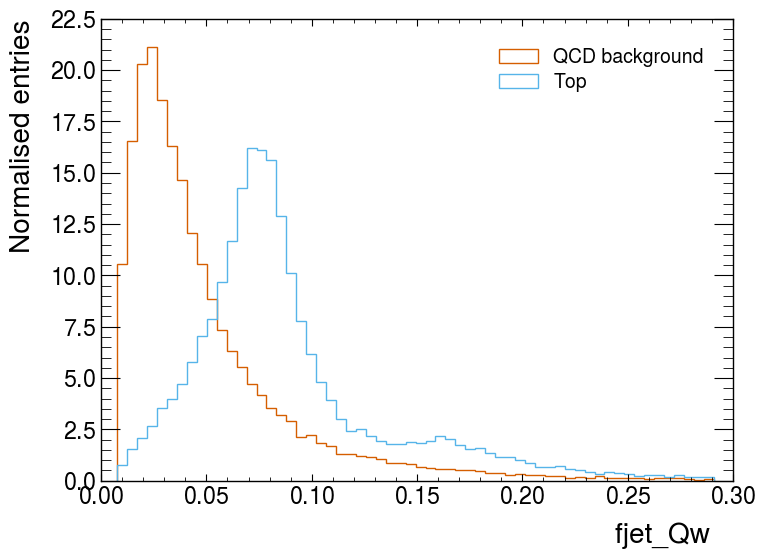

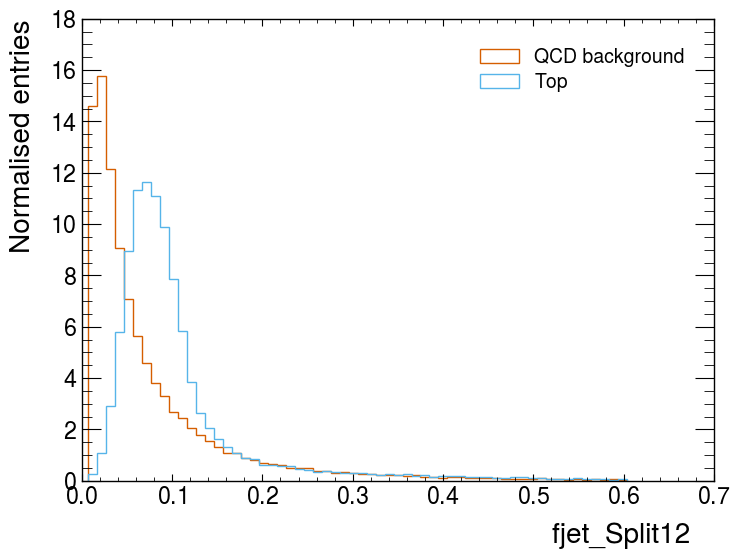

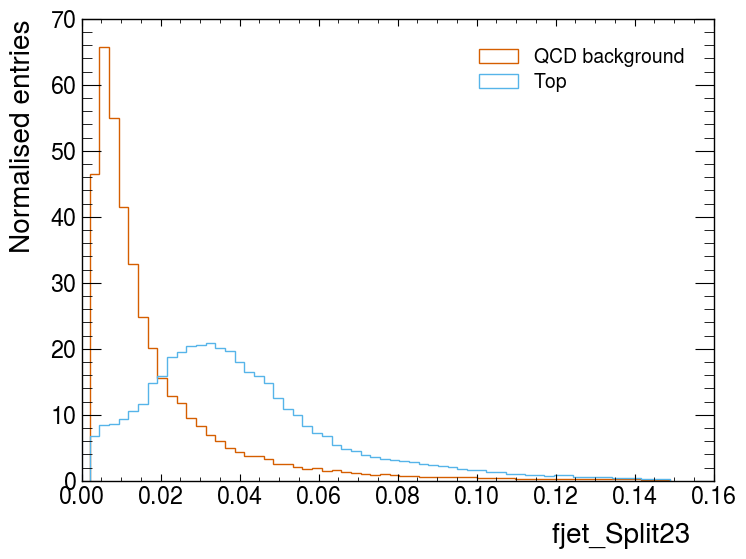

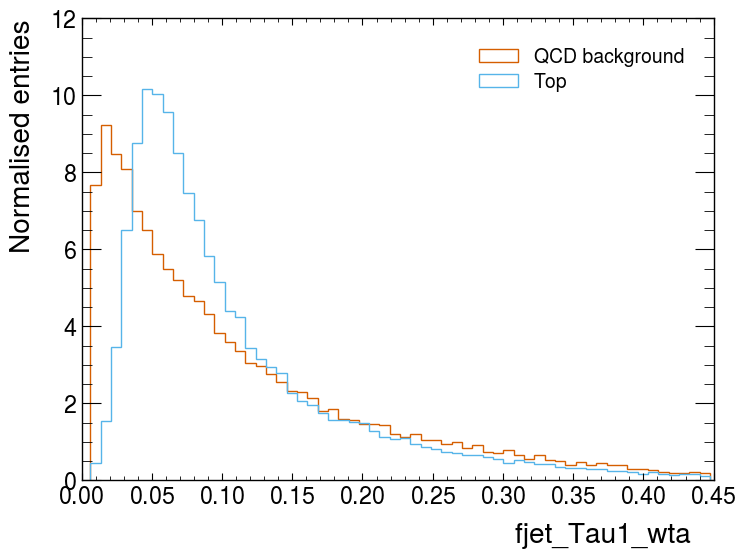

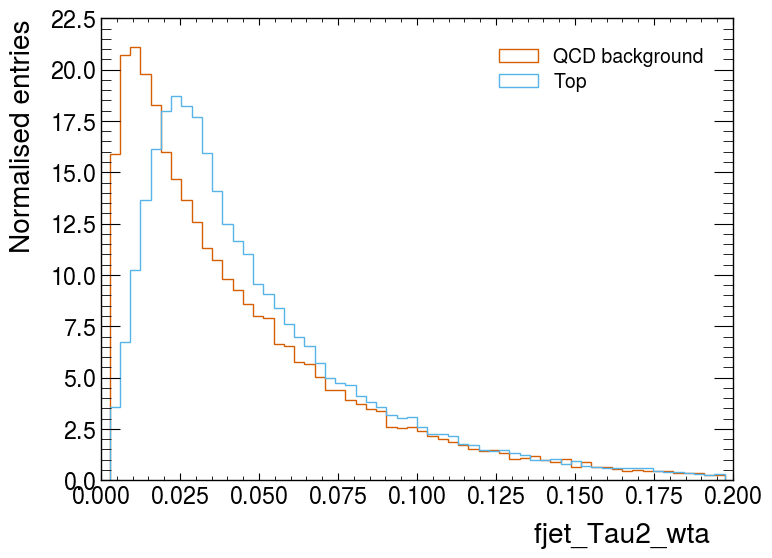

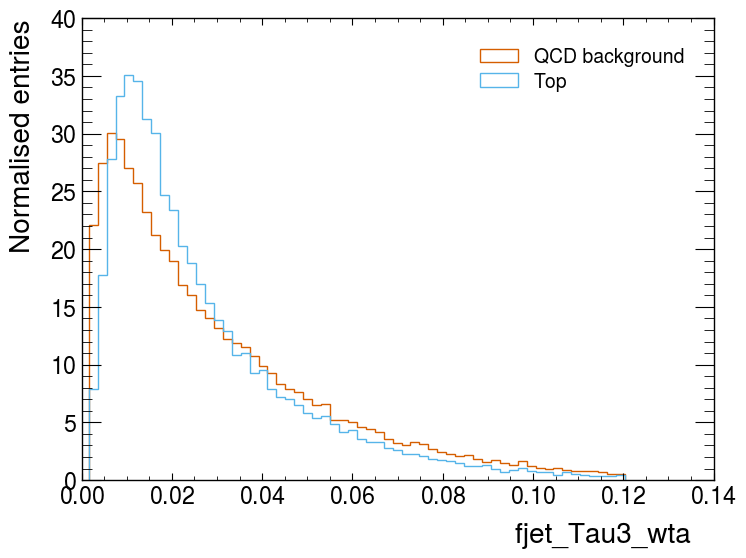

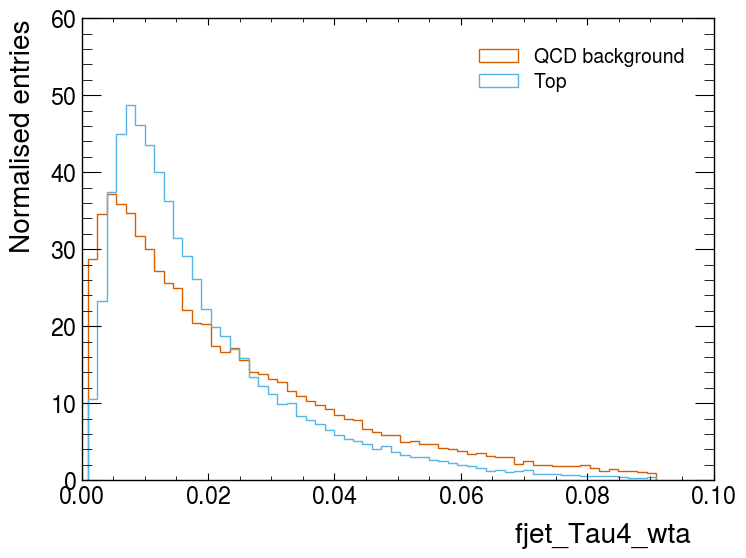

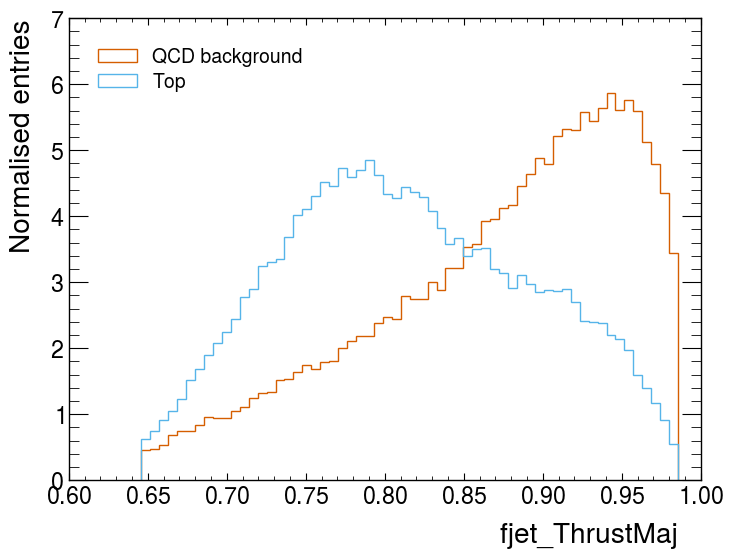

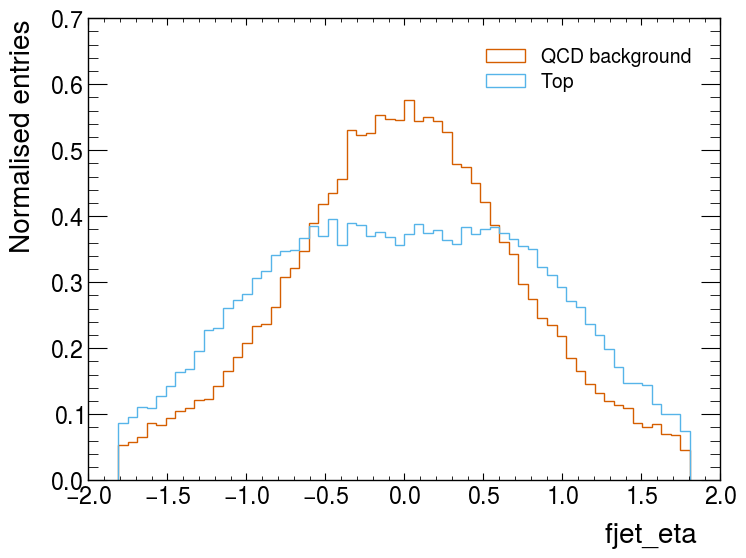

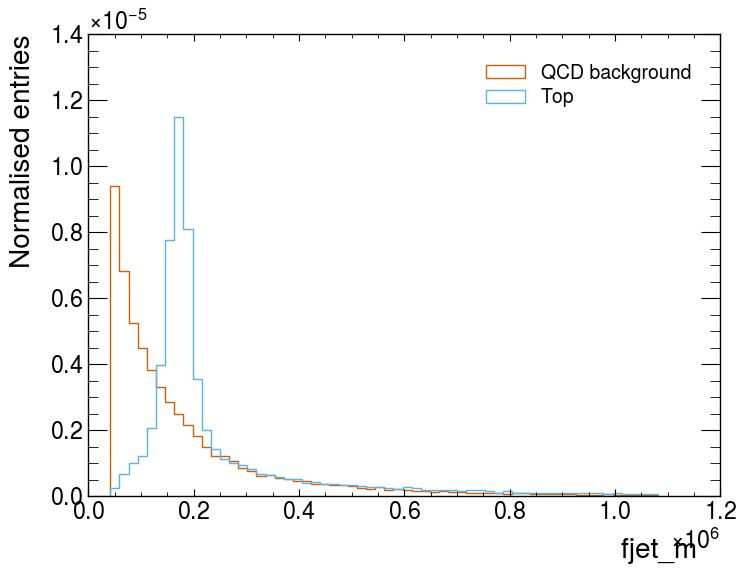

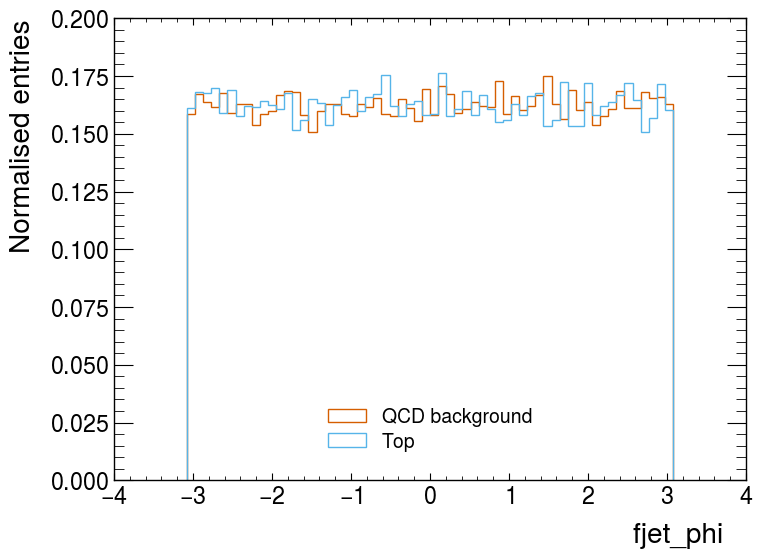

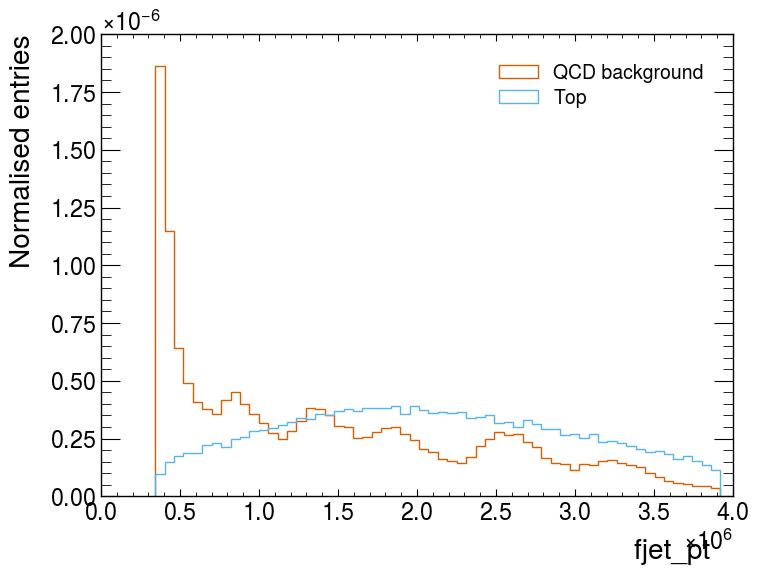

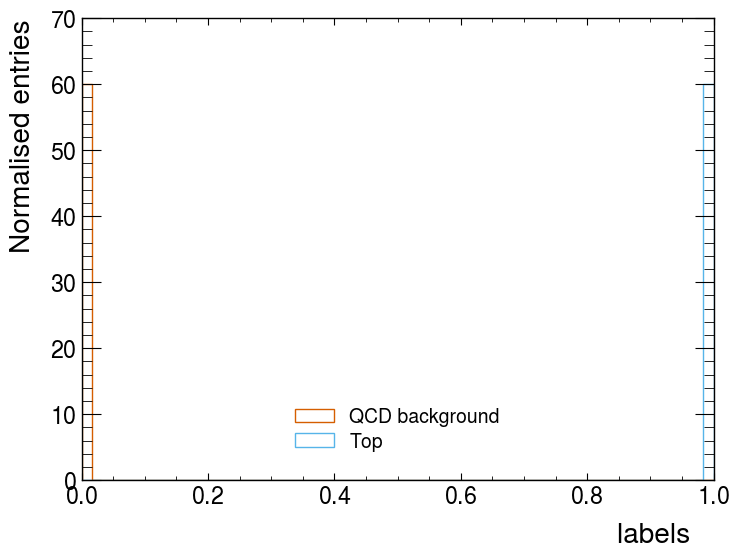

In [26]:
import matplotlib.pyplot as plt, mplhep as hep  # mplhep adds particle-physics plot styles
hep.style.use("ATLAS")  # uses the ATLAS publication style
top_quark_jets, background = df[df.labels == 1], df[df.labels == 0]
for col in df.columns:
    plt.figure()
    plt.hist(background[col], bins=60, histtype="step", density=True, label="QCD background", range=(df[col].quantile(0.01), df[col].quantile(0.99)))
    plt.hist(top_quark_jets[col], bins=60, histtype="step", density=True, label="Top", range=(df[col].quantile(0.01), df[col].quantile(0.99)))
    plt.xlabel(col); plt.ylabel("Normalised entries"); plt.legend(); plt.show()